In [2]:
import torch
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import graph_utils as gu


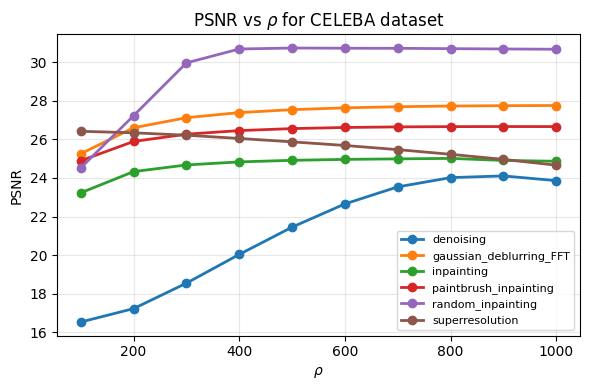

Saved: results/afhq_cat_admm_rho_graph/ot/psnr_vs_rho_admm.png


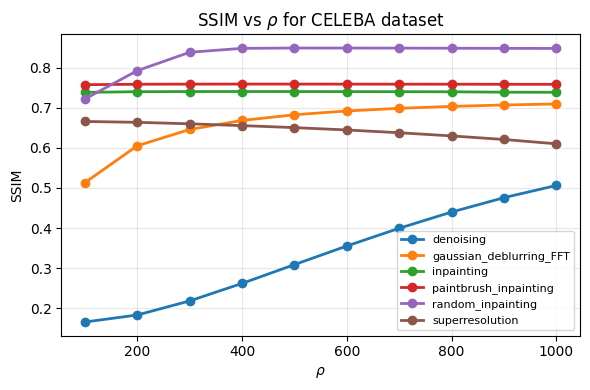

Saved: results/afhq_cat_admm_rho_graph/ot/ssim_vs_rho_admm.png


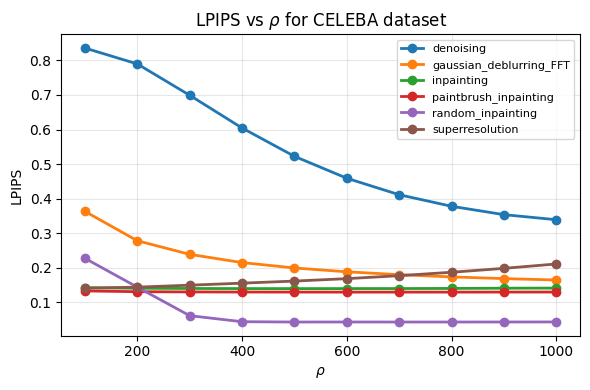

Saved: results/afhq_cat_admm_rho_graph/ot/lpips_vs_rho_admm.png


In [5]:
BASE_DIR = Path("results/afhq_cat_admm_rho_graph/ot")
METHODS = [
    "denoising",
    "gaussian_deblurring_FFT",
    "inpainting",
    "paintbrush_inpainting",
    "random_inpainting",
    "superresolution",
]
METRIC_CONFIG = {
    "final_psnr.txt":  ("psnr_rec", "PSNR"),
    "final_ssim.txt":  ("ssim_rec", "SSIM"),
    "final_lpips.txt": ("lpips_rec", "LPIPS"),   
}

for metric_file, (y_col, ylabel) in METRIC_CONFIG.items():
    save_name = f"{ylabel.lower()}_vs_rho_admm.png"
    gu.plot_all_methods(
        base_dir=BASE_DIR,
        methods=METHODS,
        metric_file=metric_file,
        y_col=y_col,
        ylabel=ylabel,
        save_name=save_name
    )


## Ablations

In [2]:
ROOT_DIR = Path("results/afhq_cat/ot")
OUT_CSV = "ablation_summary.csv"
OUT_XLSX = "ablation_summary.xlsx"

# Methods you care about
METHODS = {
    "pnp_flow_admm": "adaptive_noise",
    "pnp_flow_fbs": "random_noise",
}

METRIC_FILES = {
    "psnr": "final_psnr.txt",
    "ssim": "final_ssim.txt",
    "lpips": "final_lpips.txt",
}

df = gu.collect_results(METHODS, METRIC_FILES, ROOT_DIR)
if df.empty:
    print("No matching results found.")
else:
    gu.save_outputs(df, OUT_CSV, OUT_XLSX)
    print(f"Saved CSV  : {OUT_CSV}")
    print(f"Saved Excel: {OUT_XLSX}")
    print("\nPreview:")

Saved CSV  : ablation_summary.csv
Saved Excel: ablation_summary.xlsx

Preview:


## Results on single image for comparison

In [3]:
ROOT_DIR = Path("results/afhq_cat_rho_500_steps_250/ot")

df = gu.extract_basic_metrics(ROOT_DIR, "metrics.xlsx")
display(df)

,task,method,ssim_rec,ssim_noisy,lpips_rec,lpips_noisy,psnr_rec,psnr_noisy
0,denoising,pnp_flow_admm,0.3750,0.1843,0.4124,0.7636,22.4523,16.4813
1,gaussian_deblurring_FFT,pnp_flow_admm,0.6795,0.5227,0.1652,0.4395,26.8240,24.1778
2,inpainting,pnp_flow_admm,0.7645,0.7387,0.1040,0.2026,25.5713,21.7627
3,paintbrush_inpainting,pnp_flow_admm,0.7847,0.7614,0.0936,0.1596,27.2052,23.0488
4,random_inpainting,pnp_flow_admm,0.8538,0.2408,0.0434,1.0663,30.3248,13.8354
5,superresolution,pnp_flow_admm,0.6389,0.2294,0.1564,0.8813,25.1541,12.1581


In [4]:
ROOT_DIR = Path("results/celeba_100_rho_1000/ot")
df = gu.extract_basic_metrics(ROOT_DIR, "celeba_100_rho_1000.xlsx")
display(df)

,task,method,ssim_rec,ssim_noisy,lpips_rec,lpips_noisy,psnr_rec,psnr_noisy
0,denoising,d_flow,0.4278,0.2336,0.1832,0.5789,22.3760,16.4796
1,denoising,flow_priors,0.5439,0.2336,0.2042,0.5789,23.8527,16.4796
2,denoising,ot_ode,0.8055,0.2299,0.0487,0.5838,28.6808,16.4785
3,denoising,pnp_flow_admm,0.6074,0.2299,0.1818,0.5838,20.2635,16.4785
4,denoising,pnp_flow_fbs,0.8652,0.2299,0.0958,0.5838,29.8366,16.4785
5,gaussian_deblurring_FFT,d_flow,0.8255,0.7404,0.0976,0.1265,28.4760,27.7957
6,gaussian_deblurring_FFT,flow_priors,0.8724,0.7404,0.0393,0.1265,30.2958,27.7957
7,gaussian_deblurring_FFT,ot_ode,0.9205,0.7396,0.0307,0.1278,33.0709,27.9900
8,gaussian_deblurring_FFT,pnp_flow_admm,0.8199,0.7396,0.0728,0.1278,31.2602,27.9900
9,gaussian_deblurring_FFT,pnp_flow_fbs,0.8280,0.7396,0.1454,0.1278,28.1927,27.9900


## Empirical Convergence

Saved: results/afhq_cat_convergence_analysis/ot/norms_comparison_plots/primal_res_batch_0.png


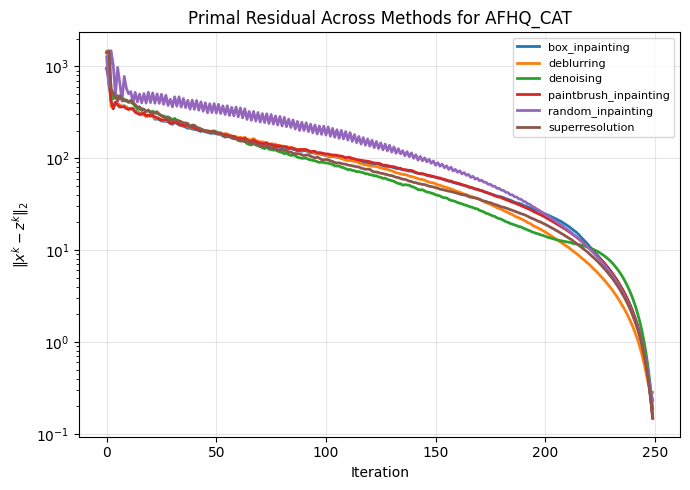

Saved: results/afhq_cat_convergence_analysis/ot/norms_comparison_plots/dual_res_batch_0.png


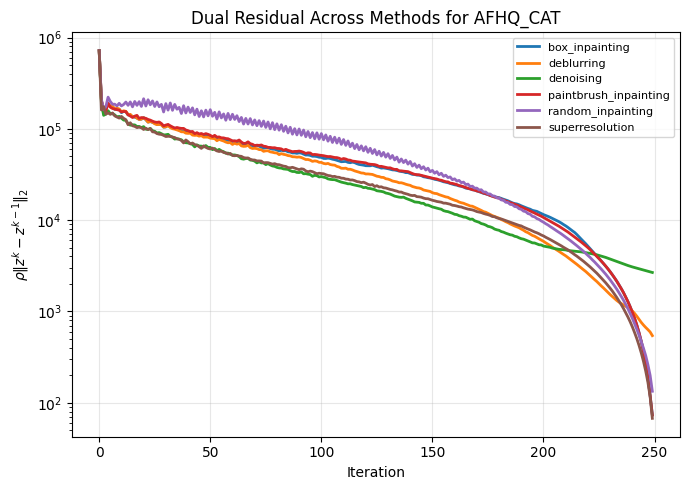

Saved: results/afhq_cat_convergence_analysis/ot/norms_comparison_plots/u_inc_batch_0.png


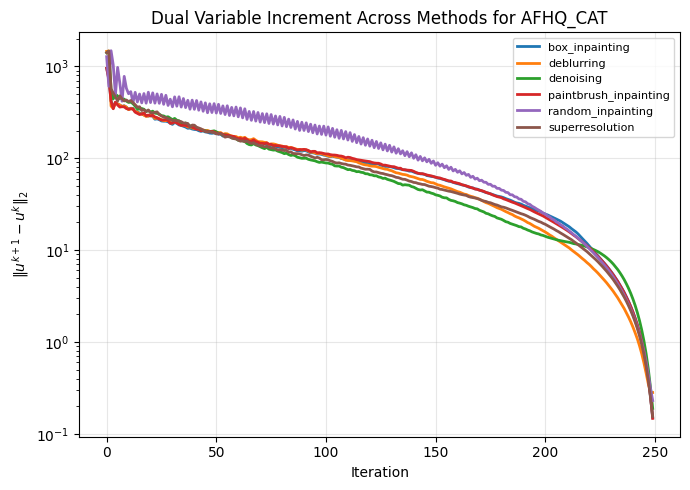

In [4]:
root_dir = Path("results/afhq_cat_convergence_analysis/ot")

gu.plot_all_norms_across_methods(
    root_dir=root_dir,
    batch=0,
    save_dir=root_dir / "norms_comparison_plots",
    logy=True,
    dataset_name='AFHQ_CAT'
)

## Time and Memory

In [3]:
root_dir = Path("results/afhq_cat/ot")

df_time_memory = gu.extract_time_memory_summary(root_dir)
gu.save_time_memory_summary(df_time_memory,xlsx_path="time_memory_summary_afhq_cat.xlsx")
display(df_time_memory)

,task,method,model,time_average,max_memory_average_gb,experiment_dir
0,denoising,d_flow,test,114.6284,66.843445,results/afhq_cat/ot/denoising/d_flow/test/step...
1,denoising,flow_priors,test,75.6776,33.214382,results/afhq_cat/ot/denoising/flow_priors/test...
2,denoising,ot_ode,test,10.0980,8.462824,results/afhq_cat/ot/denoising/ot_ode/test/step...
3,denoising,pnp_flow_admm,test,10.0219,0.788140,results/afhq_cat/ot/denoising/pnp_flow_admm/te...
4,denoising,pnp_flow_fbs,test,19.6060,0.770073,results/afhq_cat/ot/denoising/pnp_flow_fbs/tes...
5,gaussian_deblurring_FFT,d_flow,test,114.9714,66.852982,results/afhq_cat/ot/gaussian_deblurring_FFT/d_...
6,gaussian_deblurring_FFT,flow_priors,test,75.7388,33.218819,results/afhq_cat/ot/gaussian_deblurring_FFT/fl...
7,gaussian_deblurring_FFT,ot_ode,test,10.1231,8.488789,results/afhq_cat/ot/gaussian_deblurring_FFT/ot...
8,gaussian_deblurring_FFT,pnp_flow_admm,test,10.8990,0.788887,results/afhq_cat/ot/gaussian_deblurring_FFT/pn...
9,gaussian_deblurring_FFT,pnp_flow_fbs,test,19.6443,0.776582,results/afhq_cat/ot/gaussian_deblurring_FFT/pn...
